# Building Perceptron — Développement de la classe & nettoyage des données

**Contenu de ce notebook**
1. Développement et validation de la classe `Perceptron` (données factices)
2. Chargement et nettoyage du jeu de données *Breast Cancer Wisconsin (Diagnostic)*



In [28]:
import sys; sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import make_blobs, make_moons
from sklearn.linear_model import Perceptron as SkPerceptron
from perceptron import Perceptron

sns.set_theme(style="whitegrid")

from pathlib import Path
Path("../images").mkdir(exist_ok=True)   # dossier des graphiques exportés

## 1. La classe `Perceptron`

**Principe.** Pour une observation $x$, le perceptron calcule l'entrée nette $z = w \cdot x + b$
puis applique la fonction de Heaviside : $\hat y = 1$ si $z \geq 0$, sinon $0$.

**Règle de Rosenblatt** (mise à jour après chaque exemple) :
$$\Delta w = \eta\,(y - \hat y)\,x \qquad \Delta b = \eta\,(y - \hat y)$$
Si la prédiction est correcte, $y-\hat y=0$ : rien ne change. Sinon, l'hyperplan est déplacé vers l'exemple mal classé.

| Élément | Rôle |
|---|---|
| `__init__` | hyperparamètres : `eta`, `n_iter`, `shuffle`, `random_state`, `early_stopping` |
| `fit` | initialise $w$ (petites valeurs aléatoires), $b=0$, boucle sur les epochs, remplit `errors_` |
| `net_input` | calcule $w\cdot x + b$ |
| `_activation` | Heaviside |
| `predict` / `decision_function` / `score` | inférence, distance à l'hyperplan, accuracy |

### 1.1 Test sur données linéairement séparables
Deux blobs gaussiens bien séparés : le perceptron doit converger (0 erreur) — c'est le théorème de convergence de Rosenblatt.

In [29]:
X, y = make_blobs(n_samples=200, centers=2, cluster_std=1.0, random_state=1)
p = Perceptron(eta=0.1, n_iter=50, random_state=0).fit(X, y)
print(p)
print(f"Accuracy : {p.score(X, y):.3f} | epochs effectuées : {p.n_iter_} | erreurs/epoch : {p.errors_}")

Perceptron(eta=0.1, n_iter=50, shuffle=True, random_state=0)
Accuracy : 1.000 | epochs effectuées : 2 | erreurs/epoch : [2, 0]


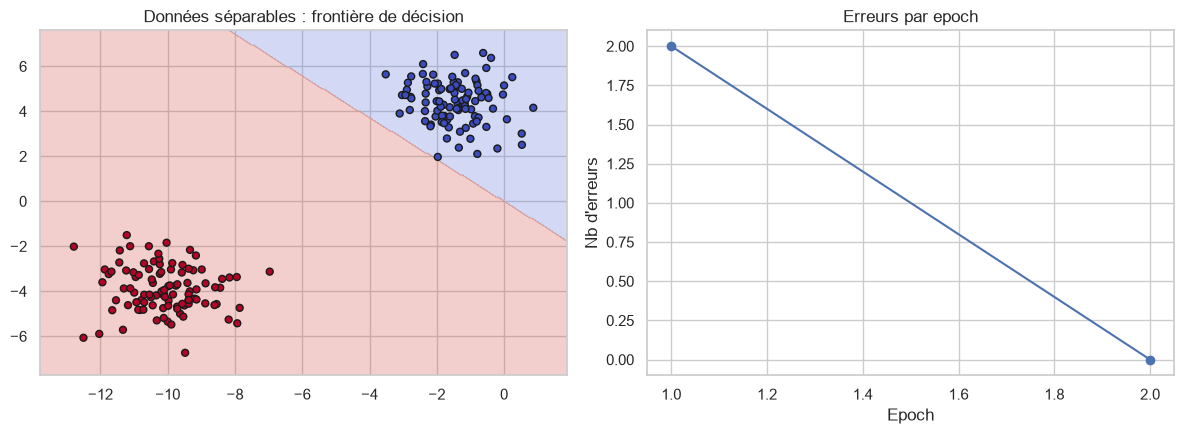

In [30]:
def plot_decision(model, X, y, ax, title):
    x0, x1 = np.meshgrid(np.linspace(X[:,0].min()-1, X[:,0].max()+1, 300),
                         np.linspace(X[:,1].min()-1, X[:,1].max()+1, 300))
    Z = model.predict(np.c_[x0.ravel(), x1.ravel()]).reshape(x0.shape)
    ax.contourf(x0, x1, Z, alpha=0.25, cmap="coolwarm")
    ax.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", edgecolor="k", s=25)
    ax.set_title(title)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
plot_decision(p, X, y, ax[0], "Données séparables : frontière de décision")
ax[1].plot(range(1, len(p.errors_)+1), p.errors_, marker="o")
ax[1].set(title="Erreurs par epoch", xlabel="Epoch", ylabel="Nb d'erreurs")
plt.tight_layout(); plt.savefig("../images/perceptron_separable.png", dpi=150); plt.show()

**Interprétation.** La frontière (droite) sépare parfaitement les deux nuages et le nombre d'erreurs tombe à 0 en quelques epochs : le perceptron a convergé.

### 1.2 Test sur données non séparables (limite du perceptron)
Avec `make_moons` (deux demi-lunes imbriquées) aucune droite ne peut séparer les classes : le perceptron ne peut pas converger.

Accuracy : 0.815 | epochs : 100 | dernières erreurs : [33, 33, 34, 37, 42]


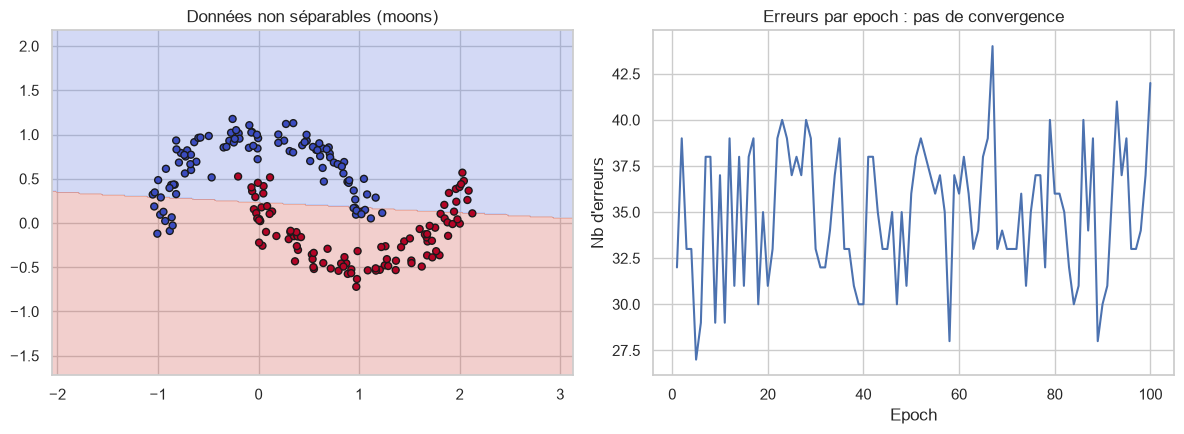

In [31]:
Xm, ym = make_moons(n_samples=200, noise=0.1, random_state=1)
pm = Perceptron(eta=0.1, n_iter=100, random_state=0).fit(Xm, ym)
print(f"Accuracy : {pm.score(Xm, ym):.3f} | epochs : {pm.n_iter_} | dernières erreurs : {pm.errors_[-5:]}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
plot_decision(pm, Xm, ym, ax[0], "Données non séparables (moons)")
ax[1].plot(range(1, len(pm.errors_)+1), pm.errors_)
ax[1].set(title="Erreurs par epoch : pas de convergence", xlabel="Epoch", ylabel="Nb d'erreurs")
plt.tight_layout(); plt.savefig("../images/perceptron_moons.png", dpi=150); plt.show()

**Interprétation.** Les erreurs oscillent sans jamais atteindre 0 : la frontière linéaire ne peut pas épouser la forme des classes. C'est la limite fondamentale mise en évidence par Minsky & Papert (1969) avec le problème XOR.

### 1.3 Comparaison avec `scikit-learn`

In [32]:
rows = []
for name, (A, b) in {"blobs": (X, y), "moons": (Xm, ym)}.items():
    rows.append({"jeu": name,
                 "Perceptron (le nôtre)": Perceptron(0.1, 100, random_state=0).fit(A, b).score(A, b),
                 "sklearn Perceptron": SkPerceptron(eta0=0.1, max_iter=100, random_state=0).fit(A, b).score(A, b)})
pd.DataFrame(rows).set_index("jeu").round(3)

,Perceptron (le nôtre),sklearn Perceptron
jeu,,
blobs,1.000,1.000
moons,0.815,0.835


Les performances sont comparables : notre implémentation se comporte comme celle de `scikit-learn` (écarts dus à l'initialisation et à l'ordre des exemples).

## 2. Données : Breast Cancer Wisconsin (Diagnostic)

Source : UCI ML Repository. 569 tumeurs ; pour chaque noyau cellulaire, 10 caractéristiques (rayon, texture, périmètre, aire, lissage, compacité, concavité, points concaves, symétrie, dimension fractale) résumées par 3 statistiques : **moyenne** (`_mean`), **erreur standard** (`_se`) et **pire valeur** (`_worst`) → 30 variables. La cible `diagnosis` vaut M (maligne) ou B (bénigne).

In [34]:
df = pd.read_csv(r"C:\Users\lisac\Downloads\files\building-perceptron\bp\data\bcw_data.csv")
print("Dimensions :", df.shape)
df.head()

Dimensions : (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

**Constat.** Le fichier contient 33 colonnes alors que la description n'en prévoit que 32 (id + diagnosis + 30 variables) : une colonne `Unnamed: 32` apparaît, intégralement vide. Elle provient de la virgule finale présente à la fin de chaque ligne du CSV.

In [36]:
# 1) Valeurs manquantes
na = df.isna().sum()
print(na[na > 0])

Unnamed: 32    569
dtype: int64


In [37]:
# 2a) Unicité de l'identifiant (à faire AVANT de supprimer 'id')
print("Nombre d'id :", df["id"].shape[0])
print("Id uniques  :", df["id"].nunique())
print("Id dupliqués :", df["id"].duplicated().sum())

Nombre d'id : 569
Id uniques  : 569
Id dupliqués : 0


Chaque `id` apparaît une seule fois (569 id uniques pour 569 lignes) : aucun patient n'est présent en double. On peut donc supprimer `id` sans risque de fuite ou de doublon caché.

In [38]:
# 2) Suppression de la colonne vide (100 % NaN) et de l'identifiant (sans valeur prédictive)
assert df["Unnamed: 32"].isna().all()
df = df.drop(columns=["Unnamed: 32", "id"])
df.shape

(569, 31)

In [39]:
# 3) Doublons, valeurs manquantes restantes, types
print("Doublons :", df.duplicated().sum())
print("NaN restants :", df.isna().sum().sum())
print("Types :", df.dtypes.value_counts().to_dict())

Doublons : 0
NaN restants : 0
Types : {dtype('float64'): 30, <StringDtype(storage='python', na_value=nan)>: 1}


In [40]:
# 3b) Propreté des noms de colonnes et de la cible
print("Colonnes avec espaces en début/fin :", [c for c in df.columns if c != c.strip()])
print("Modalités de diagnosis :", df["diagnosis"].unique().tolist())

Colonnes avec espaces en début/fin : []
Modalités de diagnosis : ['M', 'B']


Aucun nom de colonne ne contient d'espace parasite, et `diagnosis` ne contient que deux modalités propres (`M` et `B`) : pas de variantes de casse (`m`, `b`) ni de fautes de saisie à corriger.

Les noms contiennent néanmoins des espaces internes (ex. `concave points_mean`) : il faudra les écrire avec des crochets, `df["concave points_mean"]`.

In [41]:
# 4) Contrôle de cohérence : valeurs impossibles (négatives ou nulles pour des grandeurs physiques)
features = df.columns.drop("diagnosis")
print("Valeurs négatives :", (df[features] < 0).sum().sum())
zeros = (df[features] == 0).sum()
print("Colonnes contenant des zéros :\n", zeros[zeros > 0])

Valeurs négatives : 0
Colonnes contenant des zéros :
 concavity_mean          13
concave points_mean     13
concavity_se            13
concave points_se       13
concavity_worst         13
concave points_worst    13
dtype: int64


Les zéros apparaissent uniquement dans `concavity_*` et `concave points_*` : c'est cohérent (un contour parfaitement convexe n'a ni concavité ni point concave), il ne s'agit **pas** de valeurs manquantes déguisées. On les conserve.

In [42]:
# 4b) Cohérence entre variables
bases = ["radius", "texture", "perimeter", "area", "smoothness",
         "compactness", "concavity", "concave points", "symmetry", "fractal_dimension"]

# La pire valeur (_worst) ne peut pas être inférieure à la moyenne (_mean)
incoherent = {b: int((df[f"{b}_worst"] < df[f"{b}_mean"]).sum()) for b in bases}
print("Lignes avec worst < mean :", incoherent)

# L'écart-type (_se) ne peut pas être négatif
print("Valeurs _se négatives :", int((df[[f"{b}_se" for b in bases]] < 0).sum().sum()))

# Cohérence géométrique : périmètre ≈ 2πr et aire ≈ πr² (pour un noyau proche d'un disque)
perim_ratio = df["perimeter_mean"] / (2 * np.pi * df["radius_mean"])
area_ratio = df["area_mean"] / (np.pi * df["radius_mean"] ** 2)
print(f"périmètre / (2πr) : de {perim_ratio.min():.2f} à {perim_ratio.max():.2f}")
print(f"aire / (πr²)      : de {area_ratio.min():.2f} à {area_ratio.max():.2f}")

Lignes avec worst < mean : {'radius': 0, 'texture': 0, 'perimeter': 0, 'area': 0, 'smoothness': 0, 'compactness': 0, 'concavity': 0, 'concave points': 0, 'symmetry': 0, 'fractal_dimension': 0}
Valeurs _se négatives : 0
périmètre / (2πr) : de 0.98 à 1.13
aire / (πr²)      : de 0.92 à 1.06


**Interprétation.**
- Aucune ligne n'a une valeur `_worst` inférieure à la moyenne correspondante, et aucun écart-type n'est négatif : les trois statistiques (moyenne, erreur standard, pire valeur) sont cohérentes entre elles.
- Les rapports périmètre/(2πr) et aire/(πr²) restent proches de 1 (environ 0,98 à 1,13 et 0,92 à 1,06). Les noyaux sont donc proches de disques et les variables `radius`, `perimeter` et `area` sont cohérentes entre elles.
- Ces trois variables sont aussi fortement corrélées par construction (formules géométriques) : c'est un point à examiner pendant l'analyse exploratoire et la réduction de dimension.

In [43]:
# 5) Encodage de la cible : M (maligne) = 1, B (bénigne) = 0
print(df["diagnosis"].unique())
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0}).astype(int)
df["diagnosis"].value_counts().rename({0: "Bénigne (0)", 1: "Maligne (1)"})

<StringArray>
['M', 'B']
Length: 2, dtype: str


diagnosis
Bénigne (0)    357
Maligne (1)    212
Name: count, dtype: int64

**Déséquilibre des classes.** 357 bénignes (≈ 63 %) contre 212 malignes (≈ 37 %) : déséquilibre modéré. Il faudra un split **stratifié** et des métriques adaptées (rappel, F1, ROC-AUC) en phase de modélisation, l'accuracy seule étant trompeuse.

In [44]:
# 6) Contrôle des outliers (à titre informatif — non supprimés : valeurs médicalement plausibles)
z = (df[features] - df[features].mean()) / df[features].std()
print("Observations avec au moins une |z| > 3 :", (z.abs() > 3).any(axis=1).sum(), "/", len(df))

Observations avec au moins une |z| > 3 : 74 / 569


Quelques observations dépassent 3 écarts-types. Ce sont des tumeurs réellement grosses/irrégulières (souvent malignes) et non des erreurs de saisie : on **ne les supprime pas**, l'analyse exploratoire les examinera.

In [45]:
# 6b) Outliers par variable (règle de l'IQR : hors de [Q1 - 1,5·IQR ; Q3 + 1,5·IQR])
q1, q3 = df[features].quantile(0.25), df[features].quantile(0.75)
iqr = q3 - q1
is_outlier = (df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)

print("Lignes avec au moins un outlier IQR :", is_outlier.any(axis=1).sum(), "/", len(df))
print("\nVariables les plus concernées :")
print(is_outlier.sum().sort_values(ascending=False).head(5))
print("\nLignes concernées par classe (0 = bénigne, 1 = maligne) :")
print(is_outlier.any(axis=1).groupby(df["diagnosis"]).sum())

Lignes avec au moins un outlier IQR : 171 / 569

Variables les plus concernées :
area_se          65
radius_se        38
perimeter_se     38
area_worst       35
smoothness_se    30
dtype: int64

Lignes concernées par classe (0 = bénigne, 1 = maligne) :
diagnosis
0     57
1    114
dtype: int64


**Interprétation.** La règle de l'IQR est plus sévère que le seuil |z| > 3 : 171 lignes sur 569 ont au moins une valeur atypique, surtout sur les variables d'aire et de taille (`area_se`, `radius_se`, `perimeter_se`, `area_worst`). Les deux tiers de ces lignes (114) sont des tumeurs malignes, qui sont plus grosses et irrégulières : ces valeurs reflètent une réalité médicale et non des erreurs de mesure. On **ne les supprime donc pas** (cela retirerait de l'information utile et fausserait la distribution de la cible). Leur effet sera étudié en analyse exploratoire, et la standardisation et le choix du modèle devront en tenir compte.

In [46]:
# Sauvegarde du jeu nettoyé (le dossier et le fichier sont créés s'ils n'existent pas)
from pathlib import Path

output_path = Path("../data/bcw_clean.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)   # crée data/ si besoin
df.to_csv(output_path, index=False)                     # crée (ou écrase) le fichier

print(f"Fichier créé : {output_path.resolve()}")
print("Jeu nettoyé :", df.shape)
df.describe().T.head(8)

Fichier créé : C:\Users\lisac\Downloads\files\building-perceptron\data\bcw_clean.csv
Jeu nettoyé : (569, 31)


,count,mean,std,min,25%,50%,75%,max
diagnosis,569.0,0.372583,0.483918,0.00000,0.00000,0.00000,1.0000,1.0000
radius_mean,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
texture_mean,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
perimeter_mean,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
area_mean,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
smoothness_mean,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
compactness_mean,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.1304,0.3454
concavity_mean,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.1307,0.4268


### Bilan du nettoyage
| Étape | Action | Résultat |
|---|---|---|
| Colonne `Unnamed: 32` | supprimée (100 % vide, virgule finale du CSV) | 33 → 32 colonnes |
| Colonne `id` | supprimée (identifiant) | 31 colonnes : 30 variables + cible |
| NaN / doublons (lignes et `id`) | aucun | rien à corriger |
| Noms de colonnes / modalités de la cible | propres | rien à corriger |
| Cohérence | pas de valeur négative ; zéros légitimes | conservés |
| Cohérence worst / mean / se et géométrie | validée (worst ≥ mean, se ≥ 0, périmètre et aire cohérents avec le rayon) | rien à corriger |
| Cible | M→1, B→0 | entier, 37 % de positifs |
| Outliers | identifiés (écart à la moyenne > 3 écarts-types : 74 lignes ; règle de l'IQR : 171 lignes), conservés | à traiter en EDA |

Le jeu `data/bcw_clean.csv` (569 × 31) est prêt pour l'analyse exploratoire. **Rappel :** la standardisation sera faite *après* le split train/test (fit sur le train uniquement) pour éviter toute fuite de données.